In [94]:
#importing libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

In [95]:
#Reading the csv file
data = pd.read_csv("HTRU_2.csv")

In [3]:
data.head()

,140.5625,55.68378214,-0.234571412,-0.699648398,3.199832776,19.11042633,7.975531794,74.24222492,0
0,102.507812,58.882430,0.465318,-0.515088,1.677258,14.860146,10.576487,127.393580,0
1,103.015625,39.341649,0.323328,1.051164,3.121237,21.744669,7.735822,63.171909,0
2,136.750000,57.178449,-0.068415,-0.636238,3.642977,20.959280,6.896499,53.593661,0
3,88.726562,40.672225,0.600866,1.123492,1.178930,11.468720,14.269573,252.567306,0
4,93.570312,46.698114,0.531905,0.416721,1.636288,14.545074,10.621748,131.394004,0


In [4]:
data.tail()

,140.5625,55.68378214,-0.234571412,-0.699648398,3.199832776,19.11042633,7.975531794,74.24222492,0
17892,136.429688,59.847421,-0.187846,-0.738123,1.296823,12.166062,15.450260,285.931022,0
17893,122.554688,49.485605,0.127978,0.323061,16.409699,44.626893,2.945244,8.297092,0
17894,119.335938,59.935939,0.159363,-0.743025,21.430602,58.872000,2.499517,4.595173,0
17895,114.507812,53.902400,0.201161,-0.024789,1.946488,13.381731,10.007967,134.238910,0
17896,57.062500,85.797340,1.406391,0.089520,188.306020,64.712562,-1.597527,1.429475,0


In [5]:
data.count()

140.5625        17897
55.68378214     17897
-0.234571412    17897
-0.699648398    17897
3.199832776     17897
19.11042633     17897
7.975531794     17897
74.24222492     17897
0               17897
dtype: int64

In [96]:
#Checking the amount of each data type
data.value_counts(subset = "0")

0
0    16258
1     1639
Name: count, dtype: int64

In [97]:
#Assigning the target classes to another variable
y = data["0"]
y

0        0
1        0
2        0
3        0
4        0
        ..
17892    0
17893    0
17894    0
17895    0
17896    0
Name: 0, Length: 17897, dtype: int64

In [98]:
#Checking the correct deletion of a column
data.drop(labels = "0", axis = 1)

,140.5625,55.68378214,-0.234571412,-0.699648398,3.199832776,19.11042633,7.975531794,74.24222492
0,102.507812,58.882430,0.465318,-0.515088,1.677258,14.860146,10.576487,127.393580
1,103.015625,39.341649,0.323328,1.051164,3.121237,21.744669,7.735822,63.171909
2,136.750000,57.178449,-0.068415,-0.636238,3.642977,20.959280,6.896499,53.593661
3,88.726562,40.672225,0.600866,1.123492,1.178930,11.468720,14.269573,252.567306
4,93.570312,46.698114,0.531905,0.416721,1.636288,14.545074,10.621748,131.394004
...,...,...,...,...,...,...,...,...
17892,136.429688,59.847421,-0.187846,-0.738123,1.296823,12.166062,15.450260,285.931022
17893,122.554688,49.485605,0.127978,0.323061,16.409699,44.626893,2.945244,8.297092
17894,119.335938,59.935939,0.159363,-0.743025,21.430602,58.872000,2.499517,4.595173
17895,114.507812,53.902400,0.201161,-0.024789,1.946488,13.381731,10.007967,134.238910


In [9]:
#Deleting the column
data.drop(labels = "0", axis = 1, inplace = True)

In [99]:
#Splitting dataset, into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(data, y, test_size = 0.2, random_state = 1, stratify = y)

In [100]:
#Initializing the StandardScaler, as numbers in dataset are too high
std = StandardScaler()
std.fit(X_train)

,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [101]:
#Standardializing the data numbers
X_train_std = std.transform(X_train)
X_test_std = std.transform(X_test)

In [21]:
#First let us try off a linear kernel of SVM so we understand wether we need another kernel or not, so we leave parameters "C" and "gamma" untouched.
svc = SVC(max_iter = -1, kernel = "linear")
svc.fit(X_train_std, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [22]:
y_pred = svc.predict(X_test_std)

In [23]:
print(f"Accuracy score isL: {100 *  accuracy_score(y_pred, y_test):.3f} %")

Accuracy score isL: 98.128 %


In [30]:
'''Although the linear kernel achieves an accuracy of 98.128%, this is still misleading because of class imbalance, as noise samples outnumber pulsars. Hence, for the safety we use the 'rbf' kernel.'''

"Although the linear kernel achieves an accuracy of 98.128%, this is still misleading because of class imbalance, as noise samples outnumber pulsars. Hence, for the safety we use the 'rbf' kernel."

In [102]:
#Now we use the 'rbf' kernel
svc = SVC(C = 2.0, kernel = "rbf", max_iter = -1, gamma = 1)
svc.fit(X_train_std, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",2.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",1
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [88]:
y_pred = svc.predict(X_test_std)

In [89]:
print(f"Accuracy score isL: {100 *  accuracy_score(y_pred, y_test):.3f} %")

Accuracy score isL: 98.240 %


In [103]:
#We got nearly the same result, although this one is a little higher, but far safer than the model with linear kernel

In [92]:
def plot_decision_regions(X, y, classifier, feature_idx=(0, 1), resolution=0.02):
    markers = ('s', 'x', 'o', '^', 'v')
    colors = ('red', 'blue', 'lightgreen', 'gray', 'cyan')
    cmap = ListedColormap(colors[:len(np.unique(y))])

    x1_min, x1_max = X[:, feature_idx[0]].min() - 1, X[:, feature_idx[0]].max() + 1
    x2_min, x2_max = X[:, feature_idx[1]].min() - 1, X[:, feature_idx[1]].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))
    
    n_features = classifier.n_features_in_
    grid_points = np.zeros((xx1.ravel().shape[0], n_features))
    
    grid_points[:, feature_idx[0]] = xx1.ravel()
    grid_points[:, feature_idx[1]] = xx2.ravel()
    
    Z = classifier.predict(grid_points)
    Z = Z.reshape(xx1.shape)

    plt.contourf(xx1, xx2, Z, alpha=0.3, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())

    for idx, cl in enumerate(np.unique(y)):
        plt.scatter(x=X[y == cl, feature_idx[0]], 
                    y=X[y == cl, feature_idx[1]],
                    alpha=0.8, c=colors[idx],
                    marker=markers[idx], label=f'Class {cl}', 
                    edgecolor='black')

C:\Users\terri\AppData\Local\Temp\ipykernel_10536\3001727630.py:25: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(x=X[y == cl, feature_idx[0]],


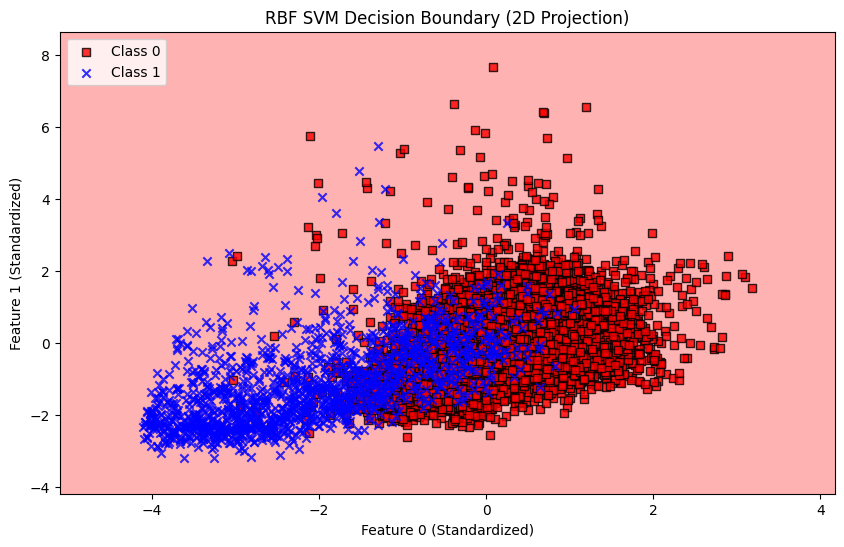

In [93]:
plt.figure(figsize=(10, 6))
plot_decision_regions(X_train_std, y_train, classifier=svc, feature_idx=(0, 1))
plt.xlabel('Feature 0 (Standardized)')
plt.ylabel('Feature 1 (Standardized)')
plt.legend(loc='upper left')
plt.title('RBF SVM Decision Boundary (2D Projection)')
plt.show()